# Global Equity Differences (working draft)

In this notebook we'll look at extending the model beyond a *US perspective*. The historical model is driven by using returns differential of US foreign and US investor. US investors or investors who park their money in the US likely account for a large proportion of international flow, but there may be some residual from external investors. This notebook will examine that and for now use a group of liquid FX futures. 

## Packages

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt
from   sklearn.decomposition import PCA

## Getting Data

In [2]:
path        = r"A:\GitHub\FXEquitySpillover\data\PrepData\FXVolTargetedReturns.parquet"
tickers     = ["EC", "JY", "AD"]
tmp_tickers = ["{}1 Curncy".format(ticker) for ticker in tickers]

df_raw_fx = pd.read_parquet(path = path, engine = "pyarrow")

df_fx = (df_raw_fx
    .loc[lambda x: x.vol_target == "perfect"]
    .loc[lambda x: x.security.isin(tmp_tickers)])

In [3]:
path      = r"A:\GitHub\FXEquitySpillover\data\FXTickerGuide.xlsx"
df_ticker = (pd
    .read_excel(io = path, sheet_name = "TickerGuide")
    .loc[lambda x: x.etf_ticker == x.etf_ticker]
    [["ticker", "name", "country", "etf_ticker"]])

In [4]:
path           = r"A:\GitHub\FXEquitySpillover\data\PrepData\ETFReturns.parquet"
df_raw_etf_rtn = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .dropna())

In [5]:
keep_tickers = (df_raw_etf_rtn
    .dropna()
    [["date", "ticker"]]
    .groupby("ticker")
    .agg("min")
    .sort_values("date")
    .assign(year = lambda x: x.date.dt.year)
    .loc[lambda x: x.year <= 2009]
    .index
    .to_list())

df_etf_rtn = (df_raw_etf_rtn
    .loc[lambda x: x.ticker.isin(keep_tickers)])

In [6]:
tickers  = df_fx.security.drop_duplicates().sort_values().to_list()
df_lists = []

for ticker in tickers: 

    ticker_dict = (df_ticker
        [["ticker", "etf_ticker"]]
        .assign(etf_ticker = lambda x: x.etf_ticker.str.split(" ").str[0])
        .set_index("ticker")
        .etf_ticker
        .to_dict())

    etf_name      = ticker_dict[ticker]
    other_tickers = (df_ticker
        .loc[lambda x: x.etf_ticker != etf_name]
        .assign(etf_ticker = lambda x: x.etf_ticker.str.split(" ").str[0])
        .etf_ticker
        .drop_duplicates()
        .to_list())

    all_tickers = other_tickers + [etf_name, "SPY"]
    df_add      = (df_etf_rtn
        .loc[lambda x: x.ticker.isin(all_tickers)]
        .pivot(index = "date", columns = "ticker", values = "rtn")
        .reset_index()
        .melt(id_vars = ["date", etf_name])
        .dropna()
        .rename(columns = {etf_name: "sov_rtn"})
        .assign(
            sov_etf    = etf_name,
            spread_rtn = lambda x: x.sov_rtn - x.value)
        .rename(columns = {"ticker": "for_etf"}))

    df_lists.append(df_add)

df_spread = pd.concat(df_lists)

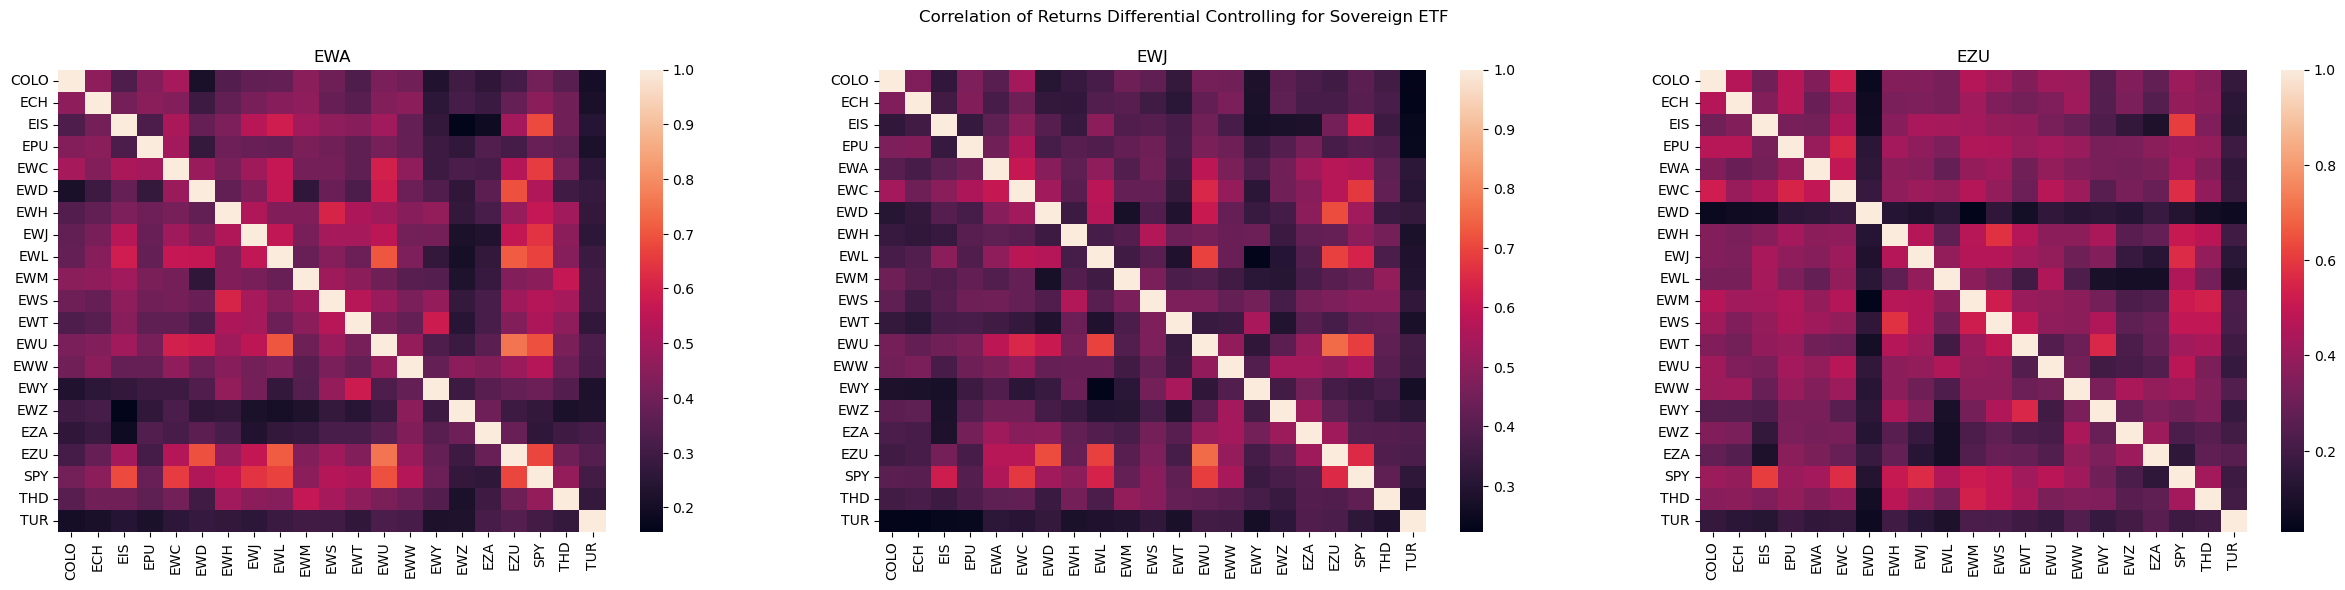

In [7]:
tickers   = df_spread.sov_etf.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = len(tickers), figsize = (30,6))

for ticker, ax in zip(tickers, axes.flatten()): 

    df_corr = (df_spread
        .loc[lambda x: x.sov_etf == ticker]
        .pivot(index = "date", columns = "for_etf", values = "spread_rtn")
        .corr())

    sns.heatmap(
        ax    = ax,
        data  = df_corr)

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(ticker)

fig.suptitle("Correlation of Returns Differential Controlling for Sovereign ETF")
plt.show()

In [8]:
df_fx_prep = (df_fx
    .rename(columns = {"security": "ticker"})
    .merge(right = df_ticker, how = "inner", on = ["ticker"])
    .assign(sov_etf = lambda x: x.etf_ticker.str.split(" ").str[0]))

In [9]:
df_combined = (df_spread
    .merge(right = df_fx_prep, how = "inner", on = ["date", "sov_etf"]))

In [10]:
def _get_ols_pred(df: pd.DataFrame) -> pd.DataFrame: 

    df_input = (df
        .pivot(index = ["date", "fx_rtn"], columns = "for_etf", values = "fx_rtn")
        .reset_index()
        .set_index(["date", "fx_rtn"])
        .shift()
        .reset_index()
        .set_index("date")
        .dropna())

    exog_cols = list(set(df_input.columns.to_list()) - set(["fx_rtn"]))
    model     = (sm
        .OLS(
            endog = df_input.fx_rtn,
            exog  = sm.add_constant(df_input[exog_cols]))
        .fit())

    df_out = (model
        .fittedvalues
        .to_frame(name = "pred"))

    return df_out

df_signal = (df_combined
    .groupby("ticker")
    .apply(_get_ols_pred)
    .reset_index()
    .rename(columns = {"pred": "pred_signal"}))

In [11]:
df_signal_rtn = (df_raw_fx
    .loc[lambda x: x.vol_target == "none"]
    .drop(columns = ["vol_target"])
    .rename(columns = {"security": "ticker"})
    .merge(right = df_signal, how = "inner", on = ["ticker", "date"])
    .assign(signal_rtn = lambda x: np.sign(x.pred_signal) * x.fx_rtn))

<Axes: xlabel='date'>

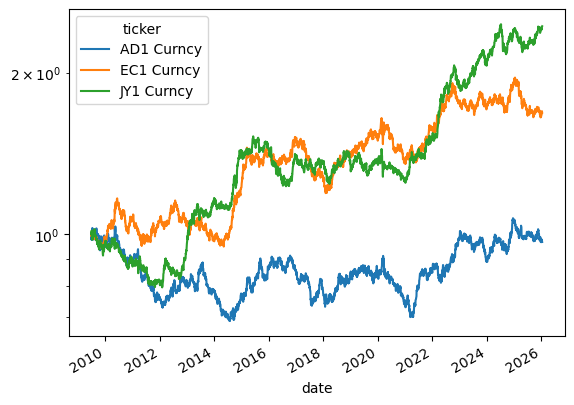

In [12]:
(df_signal_rtn
    .pivot(index = "date", columns = "ticker", values = "signal_rtn")
    .apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252))))
    .apply(lambda x: np.cumprod(1 + x))
    .plot(logy = True))

In [61]:
def _get_pca_decile_opt(df: pd.DataFrame, q: int = 10) -> pd.DataFrame: 

    df_wider = (df
        .pivot(index = "date", columns = "for_etf", values = "spread_rtn")
        .dropna())

    df_rtn = df[["date", "fx_rtn"]].drop_duplicates()

    data      = PCA(n_components = 3).fit_transform(df_wider)
    df_decile = (pd
        .DataFrame(
            data  = data,
            index = df_wider.index,
            columns = ["PC{}".format(i + 1) for i in range(3)])
        .apply(lambda x: pd.qcut(x = x, q = 10, labels = [i + 1 for i in range(10)]))
        .shift()
        .reset_index()
        .melt(id_vars = "date", value_name = "decile")
        .merge(right = df_rtn, how = "inner", on = ["date"])
        .dropna())

    df_decile_sharpe = (df_decile
        .drop(columns = ["date"])
        .groupby(["variable", "decile"])
        .agg(lambda x: x.mean() / x.std() * np.sqrt(252))
        .reset_index()
        .rename(columns = {"fx_rtn": "sharpe"}))

    df_decile_tmp = (df_decile_sharpe
        .loc[lambda x: x.decile.isin([1,2,9,10])]
        .assign(dgroup = lambda x: np.where(x.decile <= 2, "lgroup", "ugroup")))

    df_out = (df_decile_tmp
        .drop(columns = ["decile"])
        .groupby(["variable", "dgroup"])
        .agg("prod")
        .reset_index()
        .assign(signal_scaler = lambda x: np.where(x.sharpe > 0, 1, np.nan))
        .drop(columns = ["sharpe"])
        .merge(right = df_decile_tmp, how = "inner", on = ["variable", "dgroup"])
        .merge(right = df_decile    , how = "inner", on = ["variable", "decile"]))

    return df_out

df_opt = (df_combined
    .groupby("ticker")
    .apply(_get_pca_decile_opt)
    .reset_index()
    .drop(columns = ["level_1"]))

<Axes: xlabel='date'>

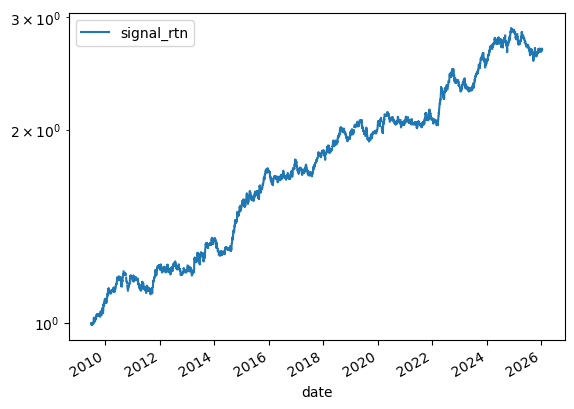

In [68]:
(df_opt
    .assign(signal_rtn = lambda x: np.sign(x.signal_scaler * x.sharpe) * x.fx_rtn)
    [["date", "signal_rtn"]]
    .groupby("date")
    .agg("mean")
    .apply(lambda x: np.cumprod(1 + x))
    .plot(logy = True))